# 01 · Data EDA  _(owner: M1)_

Explore MedAESQA, MTSamples, PLABA, MedQuAD, and a Synthea sample; build the FHIR flattener; curate the ~50-example gold set with M5.

In [22]:
import pandas as pd

df = pd.read_csv("../data/mtsamples.csv")

df.head()

,Unnamed: 0,description,medical_specialty,sample_name,transcription,keywords
0,0,A 23-year-old white female presents with comp...,Allergy / Immunology,Allergic Rhinitis,"SUBJECTIVE:, This 23-year-old white female pr...","allergy / immunology, allergic rhinitis, aller..."
1,1,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 2,"PAST MEDICAL HISTORY:, He has difficulty climb...","bariatrics, laparoscopic gastric bypass, weigh..."
2,2,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 1,"HISTORY OF PRESENT ILLNESS: , I have seen ABC ...","bariatrics, laparoscopic gastric bypass, heart..."
3,3,2-D M-Mode. Doppler.,Cardiovascular / Pulmonary,2-D Echocardiogram - 1,"2-D M-MODE: , ,1. Left atrial enlargement wit...","cardiovascular / pulmonary, 2-d m-mode, dopple..."
4,4,2-D Echocardiogram,Cardiovascular / Pulmonary,2-D Echocardiogram - 2,1. The left ventricular cavity size and wall ...,"cardiovascular / pulmonary, 2-d, doppler, echo..."


In [23]:
df.shape

(4999, 6)

In [24]:
df.columns.tolist()

['Unnamed: 0',
 'description',
 'medical_specialty',
 'sample_name',
 'transcription',
 'keywords']

In [25]:
df.head()

,Unnamed: 0,description,medical_specialty,sample_name,transcription,keywords
0,0,A 23-year-old white female presents with comp...,Allergy / Immunology,Allergic Rhinitis,"SUBJECTIVE:, This 23-year-old white female pr...","allergy / immunology, allergic rhinitis, aller..."
1,1,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 2,"PAST MEDICAL HISTORY:, He has difficulty climb...","bariatrics, laparoscopic gastric bypass, weigh..."
2,2,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 1,"HISTORY OF PRESENT ILLNESS: , I have seen ABC ...","bariatrics, laparoscopic gastric bypass, heart..."
3,3,2-D M-Mode. Doppler.,Cardiovascular / Pulmonary,2-D Echocardiogram - 1,"2-D M-MODE: , ,1. Left atrial enlargement wit...","cardiovascular / pulmonary, 2-d m-mode, dopple..."
4,4,2-D Echocardiogram,Cardiovascular / Pulmonary,2-D Echocardiogram - 2,1. The left ventricular cavity size and wall ...,"cardiovascular / pulmonary, 2-d, doppler, echo..."


In [26]:
df.isnull().sum()

Unnamed: 0              0
description             0
medical_specialty       0
sample_name             0
transcription          33
keywords             1068
dtype: int64

In [27]:
df["medical_specialty"].value_counts()

medical_specialty
Surgery                          1103
Consult - History and Phy.        516
Cardiovascular / Pulmonary        372
Orthopedic                        355
Radiology                         273
General Medicine                  259
Gastroenterology                  230
Neurology                         223
SOAP / Chart / Progress Notes     166
Obstetrics / Gynecology           160
Urology                           158
Discharge Summary                 108
ENT - Otolaryngology               98
Neurosurgery                       94
Hematology - Oncology              90
Ophthalmology                      83
Nephrology                         81
Emergency Room Reports             75
Pediatrics - Neonatal              70
Pain Management                    62
Psychiatry / Psychology            53
Office Notes                       51
Podiatry                           47
Dermatology                        29
Dentistry                          27
Cosmetic / Plastic Surgery      

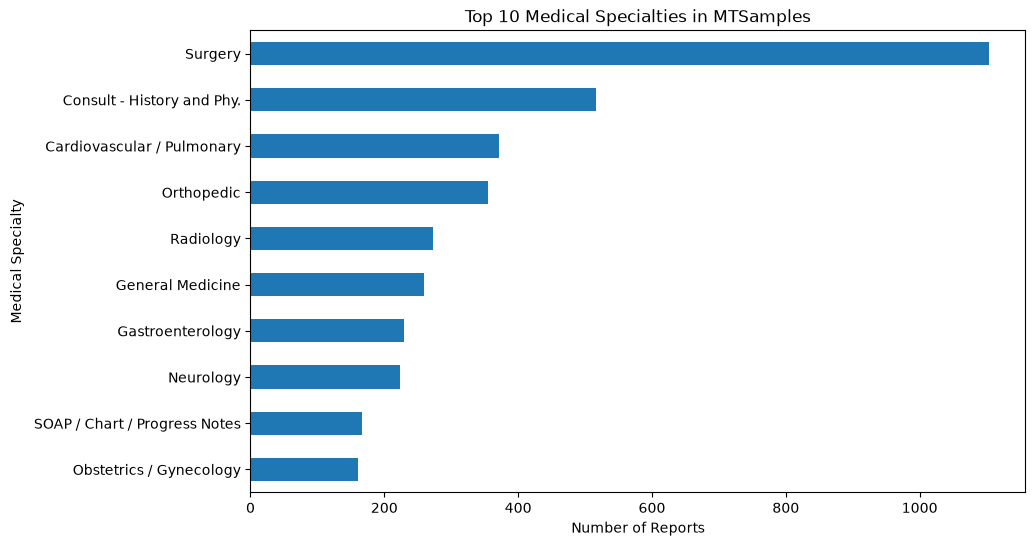

In [28]:
import matplotlib.pyplot as plt

df["medical_specialty"].value_counts().head(10).plot(
    kind="barh",
    figsize=(10, 6)
)

plt.xlabel("Number of Reports")
plt.ylabel("Medical Specialty")
plt.title("Top 10 Medical Specialties in MTSamples")
plt.gca().invert_yaxis()
plt.show()

In [29]:
df["word_count"] = df["transcription"].fillna("").apply(
    lambda text: len(text.split())
)

df["word_count"].describe()

count    4999.000000
mean      462.376275
std       317.585206
min         0.000000
25%       239.000000
50%       397.000000
75%       614.000000
max      3029.000000
Name: word_count, dtype: float64

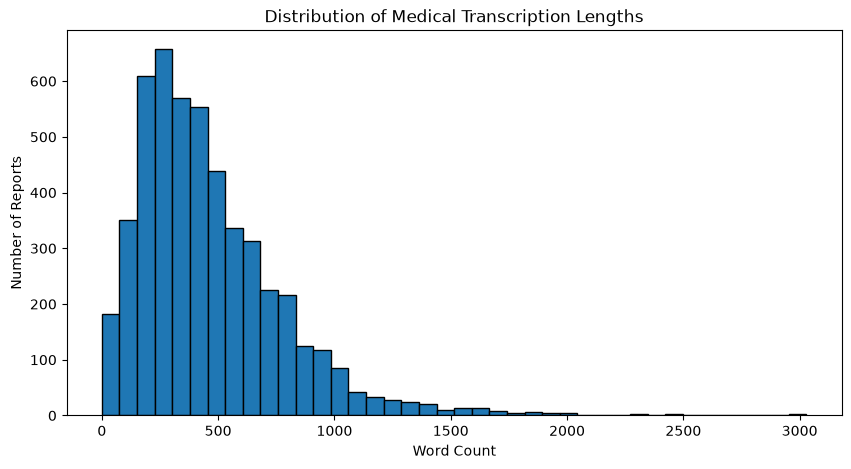

In [30]:
plt.figure(figsize=(10, 5))

plt.hist(df["word_count"], bins=40, edgecolor="black")

plt.xlabel("Word Count")
plt.ylabel("Number of Reports")
plt.title("Distribution of Medical Transcription Lengths")

plt.show()

In [31]:
df.isnull().sum()

Unnamed: 0              0
description             0
medical_specialty       0
sample_name             0
transcription          33
keywords             1068
word_count              0
dtype: int64

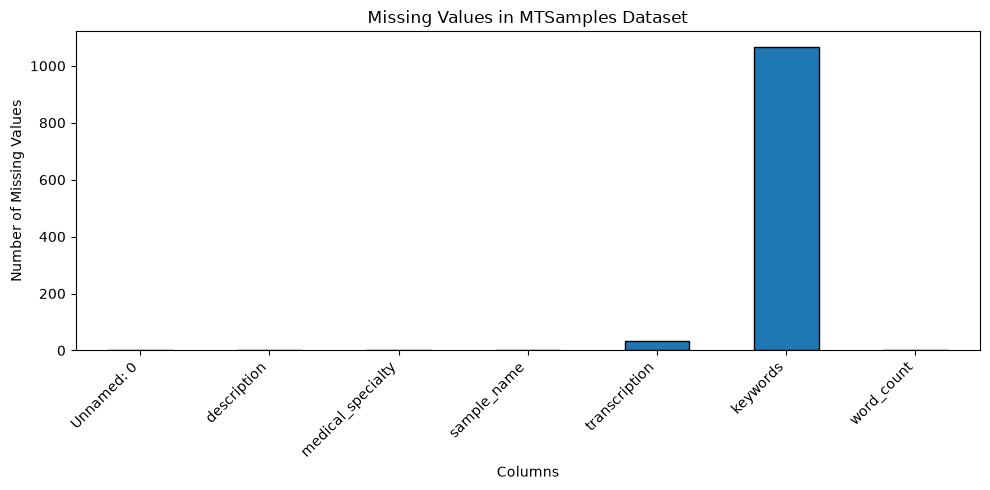

In [32]:
missing = df.isnull().sum()

plt.figure(figsize=(10, 5))

missing.plot(kind="bar", edgecolor="black")

plt.title("Missing Values in MTSamples Dataset")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [33]:
df_clean = df.dropna(subset=["transcription"]).copy()

df_clean["word_count"] = df_clean["transcription"].apply(
    lambda text: len(text.split())
)

df_clean["word_count"].describe()

count    4966.000000
mean      465.448852
std       316.386344
min         1.000000
25%       241.000000
50%       398.000000
75%       615.000000
max      3029.000000
Name: word_count, dtype: float64

In [34]:
df["word_count"].describe()

count    4999.000000
mean      462.376275
std       317.585206
min         0.000000
25%       239.000000
50%       397.000000
75%       614.000000
max      3029.000000
Name: word_count, dtype: float64

In [35]:
#mean > median --> distribution is right-skewed (some long reports are skewing the distribution)

In [36]:
df_clean = df.dropna(subset=["transcription"]).copy()

q1 = df_clean["word_count"].quantile(0.25)
q3 = df_clean["word_count"].quantile(0.75)

iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = df_clean[
    (df_clean["word_count"] < lower_bound) |
    (df_clean["word_count"] > upper_bound)
]

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of outliers:", len(outliers))

Lower bound: -320.0
Upper bound: 1176.0
Number of outliers: 155


In [37]:
outliers[
    ["medical_specialty", "sample_name", "word_count"]
].sort_values("word_count", ascending=False).head(10)

,medical_specialty,sample_name,word_count
3101,IME-QME-Work Comp etc.,Chiropractic IME - 2,3029
4610,Chiropractic,Chiropractic IME - 2,3029
3079,Letters,Chiropractic IME - 2,3029
4252,Consult - History and Phy.,Neurologic Consultation - 5,2460
2796,Neurology,Neurologic Consultation - 5,2460
4013,Dermatology,Erythema Nodosum - Consult,2332
4427,Consult - History and Phy.,Erythema Nodosum - Consult,2332
2298,Orthopedic,Bunionectomy & Arthrodesis,2019
1118,Surgery,Bunionectomy & Arthrodesis,2019
149,Urology,Cystoprostatectomy,2008


In [38]:
patient = {
    "resourceType": "Patient",
    "id": "patient-001",
    "name": [
        {
            "given": ["Alex"],
            "family": "Smith"
        }
    ],
    "gender": "female",
    "birthDate": "1990-05-15"
}

condition = {
    "resourceType": "Condition",
    "subject": {
        "reference": "Patient/patient-001"
    },
    "code": {
        "coding": [
            {
                "system": "http://snomed.info/sct",
                "code": "38341003",
                "display": "Hypertensive disorder"
            }
        ]
    },
    "clinicalStatus": {
        "coding": [
            {
                "system": "http://terminology.hl7.org/CodeSystem/condition-clinical",
                "code": "active"
            }
        ]
    }
}

In [39]:
def extract_fhir_facts(patient, condition):
    return {
        "patient_name": (
            patient["name"][0]["given"][0]
            + " "
            + patient["name"][0]["family"]
        ),
        "gender": patient["gender"],
        "birth_date": patient["birthDate"],
        "condition": condition["code"]["coding"][0]["display"],
        "condition_status": (
            condition["clinicalStatus"]["coding"][0]["code"]
        )
    }

extract_fhir_facts(patient, condition)

{'patient_name': 'Alex Smith',
 'gender': 'female',
 'birth_date': '1990-05-15',
 'condition': 'Hypertensive disorder',
 'condition_status': 'active'}

In [40]:
import json

with open("../data/Aaron697_Brekke496_2fa15bc7-8866-461a-9000-f739e425860a.json") as file:
    fhir_data = json.load(file)

print("Resource type:", fhir_data["resourceType"])
print("Number of resources:", len(fhir_data["entry"]))

Resource type: Bundle
Number of resources: 319


In [41]:
from collections import Counter

resource_types = [
    entry["resource"]["resourceType"]
    for entry in fhir_data["entry"]
]

print(Counter(resource_types))

Counter({'Observation': 187, 'Claim': 22, 'Encounter': 21, 'ExplanationOfBenefit': 21, 'DiagnosticReport': 15, 'Immunization': 13, 'Procedure': 13, 'Condition': 10, 'Goal': 5, 'Organization': 2, 'Practitioner': 2, 'CareTeam': 2, 'CarePlan': 2, 'Patient': 1, 'Device': 1, 'MedicationRequest': 1, 'ImagingStudy': 1})


In [42]:
def flatten_fhir(data):
    facts = []

    for entry in data["entry"]:
        resource = entry["resource"]
        resource_type = resource["resourceType"]

        if resource_type == "Patient":
            name = resource["name"][0]

            facts.append({
                "type": "patient",
                "name": name["given"][0] + " " + name["family"],
                "gender": resource.get("gender"),
                "birth_date": resource.get("birthDate")
            })

        elif resource_type == "Condition":
            facts.append({
                "type": "condition",
                "name": resource["code"].get("text"),
                "status": resource.get("clinicalStatus", {})
                                  .get("coding", [{}])[0]
                                  .get("code"),
                "onset": resource.get("onsetDateTime")
            })


        elif resource_type == "Observation":
            value = None
            unit = None

            if "valueQuantity" in resource:
                value = resource["valueQuantity"].get("value")
                unit = resource["valueQuantity"].get("unit")

            elif "valueCodeableConcept" in resource:
                value = resource["valueCodeableConcept"].get("text")

            elif "valueString" in resource:
                value = resource["valueString"]

            elif "valueBoolean" in resource:
                value = resource["valueBoolean"]

            elif "component" in resource:
                value = []

                for component in resource["component"]:
                    value.append({
                        "name": component["code"].get("text"),
                        "value": component.get("valueQuantity", {}).get("value"),
                        "unit": component.get("valueQuantity", {}).get("unit")
                    })

            facts.append({
                "type": "observation",
                "name": resource["code"].get("text"),
                "value": value,
                "unit": unit,
                "date": resource.get("effectiveDateTime")
            })
            

        elif resource_type == "Procedure":
            period = resource.get("performedPeriod", {})

            facts.append({
                "type": "procedure",
                "name": resource["code"].get("text"),
                "date": resource.get("performedDateTime") or period.get("start"),
                "end_date": period.get("end")
            })

        elif resource_type == "MedicationRequest":
            medication = resource.get("medicationCodeableConcept", {})

            facts.append({
                "type": "medication",
                "name": medication.get("text"),
                "status": resource.get("status")
            })

    return facts

In [43]:
flattened_data = flatten_fhir(fhir_data)

print("Number of extracted facts:", len(flattened_data))

for fact in flattened_data[:10]:
    print(fact)

Number of extracted facts: 212
{'type': 'patient', 'name': 'Aaron697 Brekke496', 'gender': 'male', 'birth_date': '1945-12-10'}
{'type': 'condition', 'name': 'Cardiac Arrest', 'status': 'active', 'onset': '1965-11-15T06:22:41-05:00'}
{'type': 'condition', 'name': 'History of cardiac arrest (situation)', 'status': 'active', 'onset': '1965-11-15T06:22:41-05:00'}
{'type': 'condition', 'name': 'Body mass index 30+ - obesity (finding)', 'status': 'active', 'onset': '1977-02-21T06:22:41-05:00'}
{'type': 'condition', 'name': 'Prediabetes', 'status': 'active', 'onset': '1987-12-21T06:22:41-05:00'}
{'type': 'condition', 'name': 'Anemia (disorder)', 'status': 'active', 'onset': '1987-12-21T06:22:41-05:00'}
{'type': 'observation', 'name': 'Body Height', 'value': 173.9018914060253, 'unit': 'cm', 'date': '2010-03-01T06:22:41-05:00'}
{'type': 'observation', 'name': 'Pain severity - 0-10 verbal numeric rating [Score] - Reported', 'value': 1.1844131388662626, 'unit': '{score}', 'date': '2010-03-01T06:2

In [44]:
from collections import Counter

missing = Counter()

for fact in flattened_data:
    for key, value in fact.items():
        if value is None:
            missing[key] += 1

print(missing)

Counter({'unit': 20})


In [51]:
original_counts = Counter(
    entry["resource"]["resourceType"]
    for entry in fhir_data["entry"]
)

flattened_counts = Counter(
    fact["type"]
    for fact in flattened_data
)

print("Original FHIR resources:")
print(original_counts)

print("\nFlattened facts:")
print(flattened_counts)

Original FHIR resources:
Counter({'Observation': 187, 'Claim': 22, 'Encounter': 21, 'ExplanationOfBenefit': 21, 'DiagnosticReport': 15, 'Immunization': 13, 'Procedure': 13, 'Condition': 10, 'Goal': 5, 'Organization': 2, 'Practitioner': 2, 'CareTeam': 2, 'CarePlan': 2, 'Patient': 1, 'Device': 1, 'MedicationRequest': 1, 'ImagingStudy': 1})

Flattened facts:
Counter({'observation': 187, 'procedure': 13, 'condition': 10, 'patient': 1, 'medication': 1})


In [46]:
for fact in flattened_data:
    if fact["type"] == "procedure":
        print(fact)
        break

{'type': 'procedure', 'name': 'Colonoscopy', 'date': '2010-12-07T06:22:41-05:00', 'end_date': '2010-12-07T06:50:41-05:00'}


In [52]:
for entry in fhir_data["entry"]:
    resource = entry["resource"]

    if resource["resourceType"] == "Observation":
        if "valueQuantity" not in resource:
            print("Name:", resource["code"].get("text"))
            print("Available fields:", list(resource.keys()))
            print()

Name: Blood Pressure
Available fields: ['resourceType', 'id', 'status', 'category', 'code', 'subject', 'encounter', 'effectiveDateTime', 'issued', 'component']

Name: Tobacco smoking status NHIS
Available fields: ['resourceType', 'id', 'status', 'category', 'code', 'subject', 'encounter', 'effectiveDateTime', 'issued', 'valueCodeableConcept']

Name: Blood Pressure
Available fields: ['resourceType', 'id', 'status', 'category', 'code', 'subject', 'encounter', 'effectiveDateTime', 'issued', 'component']

Name: Tobacco smoking status NHIS
Available fields: ['resourceType', 'id', 'status', 'category', 'code', 'subject', 'encounter', 'effectiveDateTime', 'issued', 'valueCodeableConcept']

Name: Blood Pressure
Available fields: ['resourceType', 'id', 'status', 'category', 'code', 'subject', 'encounter', 'effectiveDateTime', 'issued', 'component']

Name: Tobacco smoking status NHIS
Available fields: ['resourceType', 'id', 'status', 'category', 'code', 'subject', 'encounter', 'effectiveDateTime

/var/folders/_p/vh5l8qfx68l38g6cp3j1t_040000gp/T/ipykernel_13852/1691070709.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df_clean["word_count"], vert=False)


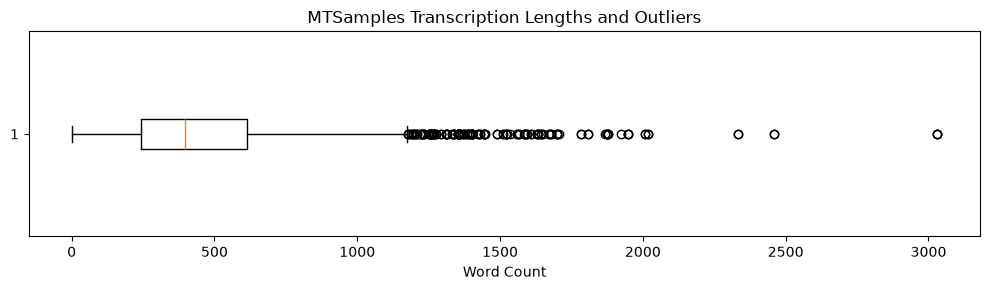

In [54]:
# Box plot: highlights the spread and unusually long transcriptions
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 3))
plt.boxplot(df_clean["word_count"], vert=False)
plt.title("MTSamples Transcription Lengths and Outliers")
plt.xlabel("Word Count")
plt.tight_layout()
plt.show()

In [55]:
# Check exact duplicates among non-empty transcription texts
normalized_text = df_clean["transcription"].str.strip()
duplicate_mask = normalized_text.duplicated(keep=False)
print("Rows with duplicated transcription text:", int(duplicate_mask.sum()))
print("Unique transcription texts:", int(normalized_text.nunique()))

df_clean.loc[duplicate_mask, ["sample_name", "medical_specialty", "word_count"]].head(15)

Rows with duplicated transcription text: 4759
Unique transcription texts: 2357


,sample_name,medical_specialty,word_count
0,Allergic Rhinitis,Allergy / Immunology,204
1,Laparoscopic Gastric Bypass Consult - 2,Bariatrics,350
2,Laparoscopic Gastric Bypass Consult - 1,Bariatrics,716
3,2-D Echocardiogram - 1,Cardiovascular / Pulmonary,68
4,2-D Echocardiogram - 2,Cardiovascular / Pulmonary,229
5,Laparoscopic Gastric Bypass,Bariatrics,728
6,Liposuction,Bariatrics,602
7,2-D Echocardiogram - 3,Cardiovascular / Pulmonary,109
8,Lipectomy - Abdomen/Thighs,Bariatrics,243
9,2-D Echocardiogram - 4,Cardiovascular / Pulmonary,57


In [56]:
# Summarize report lengths by medical specialty
specialty_summary = (
    df_clean.groupby("medical_specialty")["word_count"]
    .agg(report_count="count", median_words="median", mean_words="mean")
    .sort_values("report_count", ascending=False)
)
specialty_summary.head(10)

,report_count,median_words,mean_words
medical_specialty,,,
Surgery,1088,413.0,484.148897
Consult - History and Phy.,516,489.0,558.063953
Cardiovascular / Pulmonary,371,361.0,433.603774
Orthopedic,355,503.0,559.123944
Radiology,273,231.0,274.611722
General Medicine,259,432.0,467.096525
Gastroenterology,224,298.5,358.691964
Neurology,223,417.0,496.309417
SOAP / Chart / Progress Notes,166,283.0,358.783133


In [57]:
# Select 10 reports from different specialties, when available
eligible = df_clean.copy()
eligible = eligible[eligible["transcription"].str.strip().ne("")]
eligible = eligible.dropna(subset=["medical_specialty"])

selected_reports = (
    eligible.groupby("medical_specialty", group_keys=False)
    .sample(n=1, random_state=42)
    .sort_values("medical_specialty")
    .head(10)
    .reset_index(drop=True)
)
selected_reports.insert(0, "report_id", range(1, len(selected_reports) + 1))

print("Selected reports:", len(selected_reports))
display(selected_reports[["report_id", "medical_specialty", "sample_name", "word_count"]])

Selected reports: 10


,report_id,medical_specialty,sample_name,word_count
0,1,Allergy / Immunology,Allergic Rhinitis,204
1,2,Autopsy,Autopsy - 7,1633
2,3,Bariatrics,Gastric Bypass Summary,292
3,4,Cardiovascular / Pulmonary,Fiberoptic Bronchoscopy - 1,425
4,5,Chiropractic,Chiropractic Progress Note,835
5,6,Consult - History and Phy.,Gen Med Consult - 17,213
6,7,Cosmetic / Plastic Surgery,Blepharoplasty,323
7,8,Dentistry,Teeth (full-mouth) Extraction,391
8,9,Dermatology,MRSA Infection - ER Visit,476
9,10,Diets and Nutritions,Dietary Consult - Diabetes - 1,663


In [58]:
import inspect
import importlib

extractor_module = importlib.import_module("clearmed.agents.extractor")
print("Module file:", extractor_module.__file__)
print("Public names:", [name for name in dir(extractor_module) if not name.startswith("_")])

if hasattr(extractor_module, "extract"):
    print("extract signature:", inspect.signature(extractor_module.extract))
    print("extract documentation:", inspect.getdoc(extractor_module.extract))
else:
    print("No module-level extract() function found. Inspect extractor.py for a class or other entry point.")

Module file: /Users/chloezeng/fa26-ai-team-3/src/clearmed/agents/extractor.py
Public names: ['DEFAULT_MODEL', 'PROMPT', 'annotations', 'call_model', 'extract']
extract signature: (source: 'str', model: 'str' = 'ollama/gemma2:2b') -> 'str'
extract documentation: Return a JSON string: a list of {text, type} atoms found in `source`.


In [59]:
def run_team_extractor(report_text):
    # Replace the next line after checking the actual extractor.py implementation.
    # For example, some implementations also require a model or configuration.
    raise NotImplementedError("Connect this wrapper to your team's actual extractor API")

In [61]:
import sys
from pathlib import Path

project_root = Path.cwd().resolve().parent
sys.path.insert(0, str(project_root / "src"))

from clearmed.agents import extractor

print("Extractor file:", extractor.__file__)
print("Available functions:", [
    name for name in dir(extractor)
    if not name.startswith("_")
])

Extractor file: /Users/chloezeng/fa26-ai-team-3/src/clearmed/agents/extractor.py
Available functions: ['DEFAULT_MODEL', 'PROMPT', 'annotations', 'call_model', 'extract']


In [62]:
import inspect

print(inspect.getsource(extractor))

"""Extractor agent (owner: M1) — pull clinical "atoms" (facts + types) from the source document.

Owner TODO: structured-output prompting, schema enforcement, unit tests on 10 notes,
score recall/precision against MedAESQA "nuggets".
"""
from __future__ import annotations

from ..models import DEFAULT_MODEL, call_model

PROMPT = (
    "Extract every clinically meaningful fact from the SOURCE as a JSON list of atoms, each with "
    '{"text": ..., "type": ...} where type is one of: diagnosis, medication, lab_value, procedure, '
    "instruction. Do not add facts that are not in the SOURCE. Return only the JSON list."
)


def extract(source: str, model: str = DEFAULT_MODEL) -> str:
    """Return a JSON string: a list of {text, type} atoms found in `source`."""
    return call_model(PROMPT, f"SOURCE:\n{source}", model=model)  # dont change, for free / local ollama models to avoid api keys



In [64]:
import pandas as pd

df = pd.read_csv("../data/mtsamples.csv")

df_clean = df.dropna(subset=["transcription"]).copy()

samples = (
    df_clean.groupby("medical_specialty", group_keys=False)
    .sample(n=1, random_state=42)
    .head(10)
    .reset_index(drop=True)
)

print("Selected reports:", len(samples))

display(samples[["medical_specialty", "sample_name"]])

Selected reports: 10


,medical_specialty,sample_name
0,Allergy / Immunology,Allergic Rhinitis
1,Autopsy,Autopsy - 7
2,Bariatrics,Gastric Bypass Summary
3,Cardiovascular / Pulmonary,Fiberoptic Bronchoscopy - 1
4,Chiropractic,Chiropractic Progress Note
5,Consult - History and Phy.,Gen Med Consult - 17
6,Cosmetic / Plastic Surgery,Blepharoplasty
7,Dentistry,Teeth (full-mouth) Extraction
8,Dermatology,MRSA Infection - ER Visit
9,Diets and Nutritions,Dietary Consult - Diabetes - 1


In [68]:
result = extractor.extract(samples.iloc[0]["transcription"])
print(result)

```json
[
  {"text": "23-year-old white female", "type": "diagnosis"},
  {"text": "allergies", "type": "diagnosis"},
  {"text": "worse here", "type": "symptom"},
  {"text": "Claritin", "type": "medication"},
  {"text": "Zyrtec", "type": "medication"},
  {"text": "Allegra", "type": "medication"},
  {"text": "works for short time", "type": "symptom"},
  {"text": "lose effectiveness", "type": "symptom"},
  {"text": "over-the-counter sprays", "type": "medication"},
  {"text": "prescription nasal sprays", "type": "medication"},
  {"text": "asthma", "type": "diagnosis"},
  {"text": "daily medication", "type": "diagnosis"},
  {"text": "flaring up", "type": "symptom"},
  {"text": "Ortho Tri-Cyclen", "type": "medication"},
  {"text": "Allegra", "type": "medication"},
  {"text": "Zyrtec", "type": "medication"},
  {"text": "loratadine", "type": "medication"},
  {"text": "prescription coverage", "type": "symptom"},
  {"text": "Nasonex", "type": "medication"},
  {"text": "two sprays in each nostril

In [ ]:
import json
import pandas as pd

results = []

for i, row in samples.iterrows():
    try:
        raw = extractor.extract(row["transcription"])

        # Some models wrap JSON in Markdown code fences.
        cleaned = raw.strip()

        if cleaned.startswith("```"):
            cleaned = cleaned.split("\n", 1)[1]
            cleaned = cleaned.rsplit("```", 1)[0].strip()

        facts = json.loads(cleaned)

        if not isinstance(facts, list):
            raise ValueError("Expected a list of extracted facts")

        results.append({
            "report_id": i + 1,
            "specialty": row["medical_specialty"],
            "sample_name": row["sample_name"],
            "original_text": row["transcription"],
            "extracted_facts": json.dumps(facts),
            "fact_count": len(facts),
            "status": "success",
            "error": ""
        })

        print(f"Report {i + 1}/10: Success ({len(facts)} facts)")

    except Exception as e:
        results.append({
            "report_id": i + 1,
            "specialty": row["medical_specialty"],
            "sample_name": row["sample_name"],
            "original_text": row["transcription"],
            "extracted_facts": "",
            "fact_count": 0,
            "status": "failed",
            "error": str(e)
        })

        print(f"Report {i + 1}/10: Failed - {e}")

results_df = pd.DataFrame(results)

display(results_df[[
    "report_id", "specialty", "sample_name",
    "fact_count", "status", "error"
]])

Report 1/10: Success (22 facts)

Give Feedback / Get Help: https://github.com/BerriAI/litellm/issues/new
LiteLLM.Info: If you need to debug this error, use `litellm.turn_on_debug()'.


Provider List: https://docs.litellm.ai/docs/providers

Report 2/10: Failed - litellm.Timeout: OllamaException - litellm.Timeout: Connection timed out after 600.0 seconds.
Report 3/10: Success (23 facts)
Report 4/10: Success (31 facts)


In [ ]:
results_df.to_csv("../data/extractor_test_results.csv", index=False)

print("Successful reports:", (results_df["status"] == "success").sum())
print("Failed reports:", (results_df["status"] == "failed").sum())